## Karcher mean vs Arimetric mean: 

In [9]:
import autograd.numpy as np
import pymanopt
from pymanopt.manifolds import sphere
from pymanopt.manifolds import positive_definite
from pymanopt.tools import diagnostics

In [10]:
n=5

list_spd = []
N = 20
for i in range(N):
    M = np.random.randn(n, n)
    list_spd.append(M.T @ M + 1e-6 * np.eye(n))

mean_arith = sum(list_spd)/N

manifold = positive_definite.SymmetricPositiveDefinite(n)

In [11]:
def matrix_log(A):
    eigenvalues, U = np.linalg.eigh(A)
    return U @ np.diag(np.log(eigenvalues)) @ U.T
def matrix_power(A, p):
    eigenvalues, U = np.linalg.eigh(A)
    return U @ np.diag(eigenvalues**p) @ U.T
@pymanopt.function.autograd(manifold)
def cost(point):
    cost = 0
    for i in range(N):
        cost += np.linalg.norm( matrix_log(matrix_power(list_spd[i], -1/2) @ point @ matrix_power(list_spd[i], -1/2)))**2 
    return cost/N

def grad(point):
    grad = np.zeros((n,n))
    for i in range(N):
        grad += 2 * matrix_power(list_spd[i], 1/2) @ matrix_log(matrix_power(list_spd[i], -1/2) @ point @ matrix_power(list_spd[i], -1/2)) @ matrix_power(list_spd[i], -1/2) @ point
    return grad / N

problem = pymanopt.Problem(manifold, cost)

Directional derivative check. The slope of the continuous line should match that of the dashed (reference) line over at least a few orders of magnitude for h.


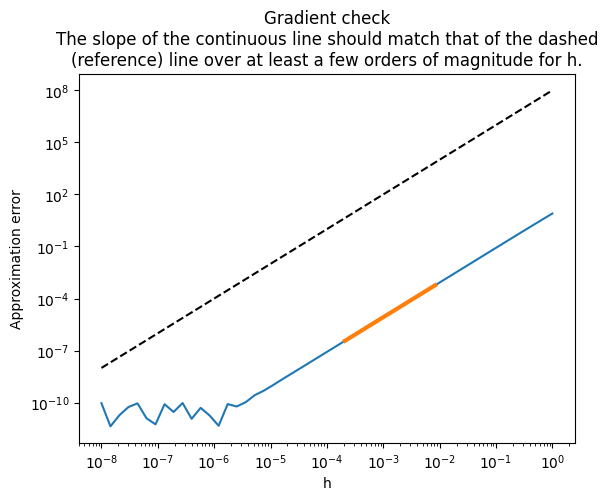

The residual should be close to 0: 0.
If it is far from 0, then the gradient is not in the tangent space.


In [12]:
x = problem.manifold.random_point()
d = grad(x)
diagnostics.check_gradient(problem, x, d)

In [13]:
for i in range(10):
    optimizer= pymanopt.optimizers.SteepestDescent(verbosity=0)
    result = optimizer.run(problem)
    mean_kar = result.point
    print(f"Run {i+1}: the Frobenius distance between 2 means: {np.linalg.norm(mean_arith - mean_kar)}")

Run 1: the Frobenius distance between 2 means: 8.658579231518992
Run 2: the Frobenius distance between 2 means: 8.658579114670145
Run 3: the Frobenius distance between 2 means: 8.658579449423566
Run 4: the Frobenius distance between 2 means: 8.658579276780673
Run 5: the Frobenius distance between 2 means: 8.658580148840738
Run 6: the Frobenius distance between 2 means: 8.658578709675414
Run 7: the Frobenius distance between 2 means: 8.658579210007485
Run 8: the Frobenius distance between 2 means: 8.658578658428661
Run 9: the Frobenius distance between 2 means: 8.658579541319583
Run 10: the Frobenius distance between 2 means: 8.658579654044749
